# 02 · Entendimento e Preparação dos Dados

Fases 2 e 3 do CRISP-DM (*Data Understanding* e *Data Preparation*). Objetivos:

1. Conhecer a estrutura da base (unidade de análise e tipos de variáveis);
2. Avaliar a qualidade dos dados (completude, duplicidades, validade, consistência e outliers);
3. Criar variáveis de apoio e salvar uma versão tratada em `data/processed/`.

Princípio adotado, como orientam as apostilas de EDA: **"desconfiar primeiro, confiar depois"** e **não alterar nem descartar dados sem justificativa**. Cada decisão fica documentada aqui.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.funcoes_nps import (
    CAMINHO_DADOS_TRATADOS, COLUNA_ALVO, COLUNAS_ATENDIMENTO, COLUNAS_CLIENTE, COLUNAS_ID,
    COLUNAS_LOGISTICA, COLUNAS_PEDIDO, COLUNAS_POS_PESQUISA, carregar_dados_brutos, classificar_nps,
)
from src.graficos import configurar_estilo, salvar_figura

configurar_estilo()
pd.set_option("display.max_columns", 50)

dados_brutos = carregar_dados_brutos()
dados_brutos.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


## 1. Estrutura da base

In [2]:
# Visão geral: quantidade de linhas, colunas, tipos e valores não nulos
dados_brutos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   object 
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64

**Unidade de análise:** cada linha é **um pedido** de um cliente. São 2.500 linhas e 19 colunas.

### 1.1 Tipos de variáveis

Classificar corretamente cada variável define quais estatísticas e gráficos fazem sentido (Aula 2 de EDA):

| Tipo | Colunas |
|---|---|
| Identificador (não é medida) | `customer_id`, `order_id` |
| Numérica contínua | `order_value`, `discount_value`, `freight_value`, `nps_score`, `csat_internal_score` |
| Numérica discreta | `customer_age`, `customer_tenure_months`, `items_quantity`, `payment_installments`, `delivery_time_days`, `delivery_delay_days`, `delivery_attempts`, `customer_service_contacts`, `resolution_time_days`, `complaints_count` |
| Categórica nominal | `customer_region` |
| Booleana (0/1) | `repeat_purchase_30d` |

E, pelo **momento da jornada** em que cada informação existe:

In [3]:
grupos_de_colunas = {
    "Identificadores": COLUNAS_ID,
    "Cliente": COLUNAS_CLIENTE,
    "Pedido": COLUNAS_PEDIDO,
    "Logística": COLUNAS_LOGISTICA,
    "Atendimento": COLUNAS_ATENDIMENTO,
    "Pós-pesquisa (não usar para prever)": COLUNAS_POS_PESQUISA,
    "Target": [COLUNA_ALVO],
}
pd.DataFrame(
    [(grupo, coluna, str(dados_brutos[coluna].dtype)) for grupo, colunas in grupos_de_colunas.items() for coluna in colunas],
    columns=["grupo", "coluna", "tipo no pandas"],
)

,grupo,coluna,tipo no pandas
0,Identificadores,customer_id,int64
1,Identificadores,order_id,int64
2,Cliente,customer_age,int64
3,Cliente,customer_region,object
4,Cliente,customer_tenure_months,int64
5,Pedido,order_value,float64
6,Pedido,items_quantity,int64
7,Pedido,discount_value,float64
8,Pedido,payment_installments,int64
9,Logística,delivery_time_days,int64


## 2. Qualidade dos dados

### 2.1 Completude e duplicidades

In [4]:
# Valores ausentes por coluna
dados_brutos.isnull().sum()

customer_id                  0
customer_age                 0
customer_region              0
customer_tenure_months       0
order_id                     0
order_value                  0
items_quantity               0
discount_value               0
payment_installments         0
delivery_time_days           0
delivery_delay_days          0
freight_value                0
delivery_attempts            0
customer_service_contacts    0
resolution_time_days         0
nps_score                    0
repeat_purchase_30d          0
complaints_count             0
csat_internal_score          0
dtype: int64

In [5]:
print(f"Linhas duplicadas: {dados_brutos.duplicated().sum()}")
print(f"order_id repetidos: {dados_brutos['order_id'].duplicated().sum()}")
print(f"customer_id repetidos: {dados_brutos['customer_id'].duplicated().sum()}  -> cada cliente aparece com um único pedido")

Linhas duplicadas: 0
order_id repetidos: 0
customer_id repetidos: 0  -> cada cliente aparece com um único pedido


A base está **completa** (nenhum valor ausente) e **sem duplicidades**. Como cada cliente aparece uma única vez, não há histórico por cliente: cada linha é uma observação independente.

### 2.2 Validade: os valores fazem sentido?

In [6]:
dados_brutos.drop(columns=COLUNAS_ID).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
customer_age,2500.0,43.40,14.89,18.00,31.00,43.00,56.00,69.00
customer_tenure_months,2500.0,61.32,34.48,1.00,31.00,62.00,91.00,119.00
order_value,2500.0,434.26,289.77,7.76,220.24,375.52,577.29,1983.81
items_quantity,2500.0,3.47,1.69,1.00,2.00,3.00,5.00,6.00
discount_value,2500.0,29.75,29.23,0.02,8.88,20.94,40.83,230.33
payment_installments,2500.0,6.00,3.16,1.00,3.00,6.00,9.00,11.00
delivery_time_days,2500.0,8.02,3.77,2.00,5.00,8.00,11.00,14.00
delivery_delay_days,2500.0,2.19,1.45,0.00,1.00,2.00,3.00,8.00
freight_value,2500.0,38.22,12.08,2.62,29.93,38.50,46.27,76.13
delivery_attempts,2500.0,2.01,0.82,1.00,1.00,2.00,3.00,3.00


In [7]:
# Contagem de categorias: procura grafias diferentes para a mesma região
dados_brutos["customer_region"].value_counts()

customer_region
Sul             521
Sudeste         520
Norte           506
Nordeste        485
Centro-Oeste    468
Name: count, dtype: int64

Os valores estão dentro de faixas plausíveis: idade entre 18 e 69 anos, nota NPS entre 0 e 10, nenhum valor negativo. As cinco regiões estão escritas de forma padronizada e têm volumes parecidos (~20% cada), o que facilita as comparações.

### 2.3 Consistência: as colunas "conversam" entre si?

Além de olhar cada coluna, checamos regras de negócio que envolvem mais de uma coluna:

In [8]:
# Cada regra descreve algo que, pela lógica do negócio, não deveria acontecer
regras_de_consistencia = {
    "atraso maior que o tempo total de entrega": dados_brutos["delivery_delay_days"] > dados_brutos["delivery_time_days"],
    "desconto maior que o valor do pedido": dados_brutos["discount_value"] > dados_brutos["order_value"],
    "tempo de resolução > 0 sem nenhum contato com o SAC": (dados_brutos["resolution_time_days"] > 0) & (dados_brutos["customer_service_contacts"] == 0),
    "reclamações registradas sem nenhum contato com o SAC": (dados_brutos["complaints_count"] > 0) & (dados_brutos["customer_service_contacts"] == 0),
    "nota NPS fora de 0-10": ~dados_brutos["nps_score"].between(0, 10),
}
pd.DataFrame({
    "linhas": {regra: int(filtro.sum()) for regra, filtro in regras_de_consistencia.items()},
    "% da base": {regra: round(100 * filtro.mean(), 1) for regra, filtro in regras_de_consistencia.items()},
})

,linhas,% da base
atraso maior que o tempo total de entrega,121,4.8
desconto maior que o valor do pedido,35,1.4
tempo de resolução > 0 sem nenhum contato com o SAC,511,20.4
reclamações registradas sem nenhum contato com o SAC,531,21.2
nota NPS fora de 0-10,0,0.0


**Interpretação e decisão:**

| Achado | Possível explicação | Decisão |
|---|---|---|
| Atraso > tempo de entrega (~5%) | `delivery_time_days` pode ser o prazo *prometido*, não o realizado | Manter; criar a marcação `flag_atraso_inconsistente`; validar a definição com a área de Logística |
| Desconto > valor do pedido (~1%) | `order_value` pode ser o valor líquido (já com desconto) | Manter; criar marcação; validar com o Financeiro |
| Resolução ou reclamações sem contato no SAC (~20%) | Reclamações podem chegar por outros canais (marketplace, redes sociais) | Manter: é plausível e traz informação |

Nenhuma linha foi removida: as inconsistências são pequenas, não afetam a target e removê-las poderia distorcer a análise. O ponto vira **recomendação de governança de dados** (dicionário com a definição exata de cada campo).

### 2.4 Outliers (valores extremos)

Primeiro olhamos visualmente, com boxplots; depois contamos com a regra do intervalo interquartil (IQR).

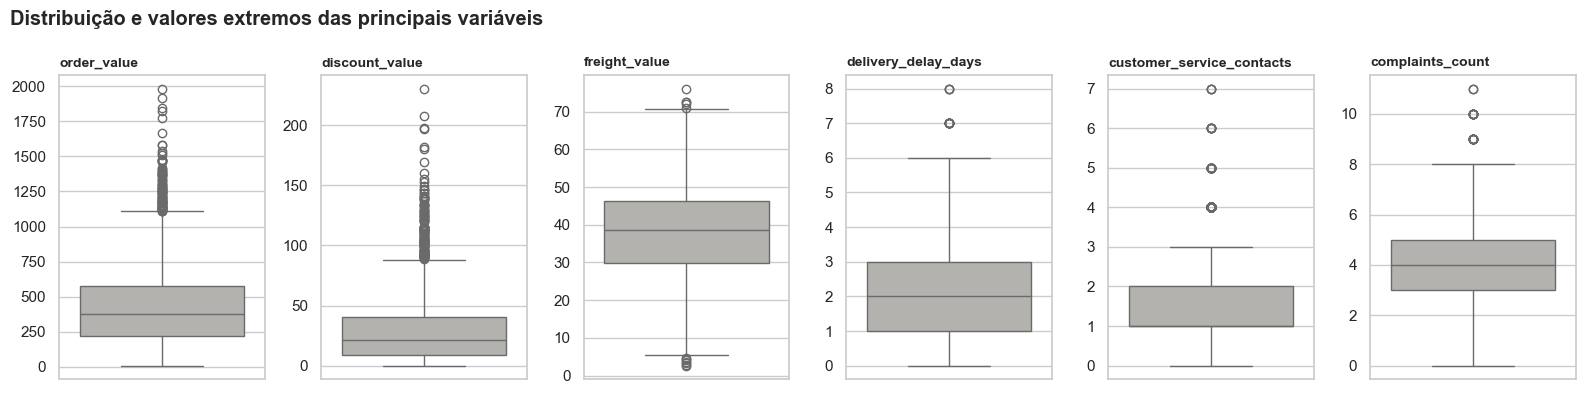

In [9]:
colunas_para_boxplot = ["order_value", "discount_value", "freight_value", "delivery_delay_days",
                        "customer_service_contacts", "complaints_count"]
figura, eixos = plt.subplots(1, len(colunas_para_boxplot), figsize=(16, 4))
for eixo, coluna in zip(eixos, colunas_para_boxplot):
    sns.boxplot(y=dados_brutos[coluna], ax=eixo, color="#b5b3ad")
    eixo.set_title(coluna, fontsize=10)
    eixo.set_ylabel("")
figura.suptitle("Distribuição e valores extremos das principais variáveis", x=0.01, ha="left", fontweight="bold")
figura.tight_layout()
salvar_figura(figura, "00_boxplots_outliers.png")
plt.show()

In [10]:
# Regra do IQR: valor extremo = abaixo de Q1 - 1,5*IQR ou acima de Q3 + 1,5*IQR
# (repeat_purchase_30d é 0/1, então não faz sentido procurar outliers nela)
colunas_numericas = dados_brutos.drop(columns=COLUNAS_ID + ["customer_region", "repeat_purchase_30d"]).columns
quantidade_outliers = {}
for coluna in colunas_numericas:
    q1 = dados_brutos[coluna].quantile(0.25)
    q3 = dados_brutos[coluna].quantile(0.75)
    iqr = q3 - q1
    fora_do_padrao = (dados_brutos[coluna] < q1 - 1.5 * iqr) | (dados_brutos[coluna] > q3 + 1.5 * iqr)
    quantidade_outliers[coluna] = int(fora_do_padrao.sum())

pd.Series(quantidade_outliers, name="qtd_outliers").sort_values(ascending=False).to_frame()

,qtd_outliers
customer_service_contacts,176
discount_value,125
order_value,84
complaints_count,29
delivery_delay_days,17
freight_value,12
customer_age,0
customer_tenure_months,0
items_quantity,0
payment_installments,0


Os valores extremos aparecem principalmente em `customer_service_contacts`, `discount_value` e `order_value`, e em menor número em `complaints_count`, `delivery_delay_days` e `freight_value`. São **eventos reais e relevantes** (pedidos grandes, atrasos longos, clientes com muitas reclamações), justamente os casos que mais interessam ao negócio. **Decisão: manter.**

## 3. Criação de variáveis de apoio (feature engineering)

Criamos variáveis que traduzem os números em **conceitos de negócio**, facilitando a EDA e a comunicação:

In [11]:
dados = dados_brutos.copy()

# --- Target em categorias (Detrator / Neutro / Promotor) ---
dados["categoria_nps"] = classificar_nps(dados["nps_score"])
dados["e_detrator"] = (dados["categoria_nps"] == "Detrator").astype(int)

# --- Logística ---
dados["entregue_no_prazo"] = (dados["delivery_delay_days"] == 0).astype(int)
dados["faixa_atraso"] = pd.cut(dados["delivery_delay_days"], bins=[-1, 0, 1, 2, 3, 100],
                               labels=["No prazo", "1 dia", "2 dias", "3 dias", "4+ dias"])

# --- Atendimento ---
dados["faixa_reclamacoes"] = pd.cut(dados["complaints_count"], bins=[-1, 1, 2, 3, 4, 5, 100],
                                    labels=["0-1", "2", "3", "4", "5", "6+"])
dados["faixa_contatos"] = pd.cut(dados["customer_service_contacts"], bins=[-1, 0, 1, 2, 3, 100],
                                 labels=["0", "1", "2", "3", "4+"])
dados["faixa_resolucao"] = pd.cut(dados["resolution_time_days"], bins=[-1, 2, 5, 8, 100],
                                  labels=["Até 2 dias", "3-5 dias", "6-8 dias", "9+ dias"])

# --- Perfil do cliente e do pedido ---
dados["faixa_idade"] = pd.cut(dados["customer_age"], bins=[17, 25, 35, 45, 55, 100],
                              labels=["18-25", "26-35", "36-45", "46-55", "56+"])
dados["faixa_tempo_casa"] = pd.cut(dados["customer_tenure_months"], bins=[0, 12, 24, 60, 1000],
                                   labels=["Até 1 ano", "1-2 anos", "2-5 anos", "5+ anos"])
dados["faixa_valor_pedido"] = pd.cut(dados["order_value"], bins=[0, 150, 300, 500, 800, 10_000],
                                     labels=["Até R$150", "R$150-300", "R$300-500", "R$500-800", "R$800+"])

# --- Marcações de qualidade de dados (seção 2.3) ---
dados["flag_atraso_inconsistente"] = (dados["delivery_delay_days"] > dados["delivery_time_days"]).astype(int)
dados["flag_desconto_inconsistente"] = (dados["discount_value"] > dados["order_value"]).astype(int)

dados[["nps_score", "categoria_nps", "faixa_atraso", "faixa_reclamacoes", "faixa_contatos", "faixa_idade"]].head()

,nps_score,categoria_nps,faixa_atraso,faixa_reclamacoes,faixa_contatos,faixa_idade
0,6.9,Detrator,2 dias,3,0,56+
1,2.4,Detrator,4+ dias,3,0,18-25
2,4.8,Detrator,1 dia,6+,4+,46-55
3,5.9,Detrator,2 dias,4,1,46-55
4,6.1,Detrator,1 dia,3,1,56+


In [12]:
# Salva a base tratada para os próximos notebooks
CAMINHO_DADOS_TRATADOS.parent.mkdir(parents=True, exist_ok=True)
dados.to_csv(CAMINHO_DADOS_TRATADOS, index=False)
print(f"Base tratada salva em data/processed/{CAMINHO_DADOS_TRATADOS.name} | formato: {dados.shape}")

Base tratada salva em data/processed/nps_tratado.csv | formato: (2500, 31)


## Resumo da preparação

- Base de **2.500 pedidos** (um por cliente), 19 colunas originais, **sem nulos e sem duplicidades**;
- Inconsistências pontuais de definição (atraso × tempo de entrega, desconto × valor) foram **marcadas, não removidas**;
- Outliers mantidos por representarem eventos reais de negócio;
- Criadas faixas (atraso, reclamações, contatos, idade, tempo de casa, valor) e a categoria NPS para a EDA;
- `repeat_purchase_30d` e `csat_internal_score` estão marcadas como **pós-pesquisa** e não entrarão no modelo.